# 04. Tối ưu hóa nâng cao
Năm cải tiến so với notebook 03:
1. **Đánh giá chắc hơn:** cross-validation lặp 5 fold x 5 lần trên toàn bộ 302 bệnh nhân (25 lần chia) thay vì một lần chia train/test 61 mẫu.
2. **Chọn ngưỡng quyết định** theo mục tiêu Recall, đánh giá bằng **nested CV** để không lạc quan giả.
3. **Hiệu chuẩn xác suất:** kiểm tra độ tin cậy của xác suất.
4. **Khoảng tin cậy bootstrap** và **kiểm tra theo giới tính**.
5. **Giải thích mô hình** (đóng góp từng đặc trưng) và huấn luyện lại mô hình cuối trên toàn bộ dữ liệu.

In [1]:
import sys; sys.path.append('..')
from src.common import *
import warnings; warnings.filterwarnings('ignore')
import json, joblib
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.calibration import calibration_curve
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, roc_auc_score, brier_score_loss)
df = load_clean(); X, y = df[FEATURES], df[TARGET]
P = lambda c: Pipeline([('prep', make_preprocessor()), ('clf', c)])
LR = lambda: LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced')
RF = lambda: RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=3, class_weight='balanced', random_state=RANDOM_STATE)
HGB = lambda: HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=150, l2_regularization=1.0, random_state=RANDOM_STATE)

## 1. So sánh mô hình bằng cross-validation lặp (5 x 5 trên 302 mẫu)
Thêm HistGradientBoosting, SVM (RBF) và một ensemble bỏ phiếu mềm (LR + RF + HGB). Siêu tham số lấy từ bước tinh chỉnh ở notebook 03 hoặc đặt bảo thủ cho dữ liệu nhỏ. Báo cáo **trung bình ± độ lệch chuẩn qua 25 lần chia**.

In [2]:
models = {'Logistic Regression': P(LR()), 'Random Forest': P(RF()), 'HistGradientBoosting': P(HGB()),
          'SVM (RBF)': P(SVC(C=1, kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE)),
          'Ensemble (LR+RF+HGB)': P(VotingClassifier([('lr', LR()), ('rf', RF()), ('hgb', HGB())], voting='soft'))}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
sc = {'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'f2': make_scorer(fbeta_score, beta=2), 'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'brier': 'neg_brier_score'}
raw, rows = {}, []
for k, m in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=sc, n_jobs=-1); raw[k] = s
    rows.append({'Mô hình': k, **{n: f"{(-1 if n=='brier' else 1)*s['test_'+n].mean():.3f} ± {s['test_'+n].std():.3f}" for n in sc}})
cmp_tab = pd.DataFrame(rows).rename(columns={'brier': 'Brier (thấp hơn tốt hơn)'}); cmp_tab.to_csv(ROOT / 'report' / 'bang_so_sanh_cv_lap.csv', index=False); cmp_tab

,Mô hình,recall,precision,f1,f2,roc_auc,pr_auc,Brier (thấp hơn tốt hơn)
0,Logistic Regression,0.804 ± 0.090,0.873 ± 0.067,0.834 ± 0.065,0.815 ± 0.079,0.917 ± 0.038,0.912 ± 0.042,0.116 ± 0.021
1,Random Forest,0.805 ± 0.083,0.833 ± 0.065,0.817 ± 0.061,0.809 ± 0.073,0.920 ± 0.035,0.916 ± 0.041,0.129 ± 0.016
2,HistGradientBoosting,0.788 ± 0.078,0.845 ± 0.065,0.813 ± 0.051,0.797 ± 0.064,0.908 ± 0.037,0.902 ± 0.045,0.122 ± 0.027
3,SVM (RBF),0.800 ± 0.079,0.839 ± 0.065,0.817 ± 0.060,0.806 ± 0.069,0.903 ± 0.043,0.898 ± 0.047,0.122 ± 0.029
4,Ensemble (LR+RF+HGB),0.797 ± 0.089,0.859 ± 0.064,0.824 ± 0.062,0.807 ± 0.077,0.919 ± 0.035,0.914 ± 0.041,0.118 ± 0.021


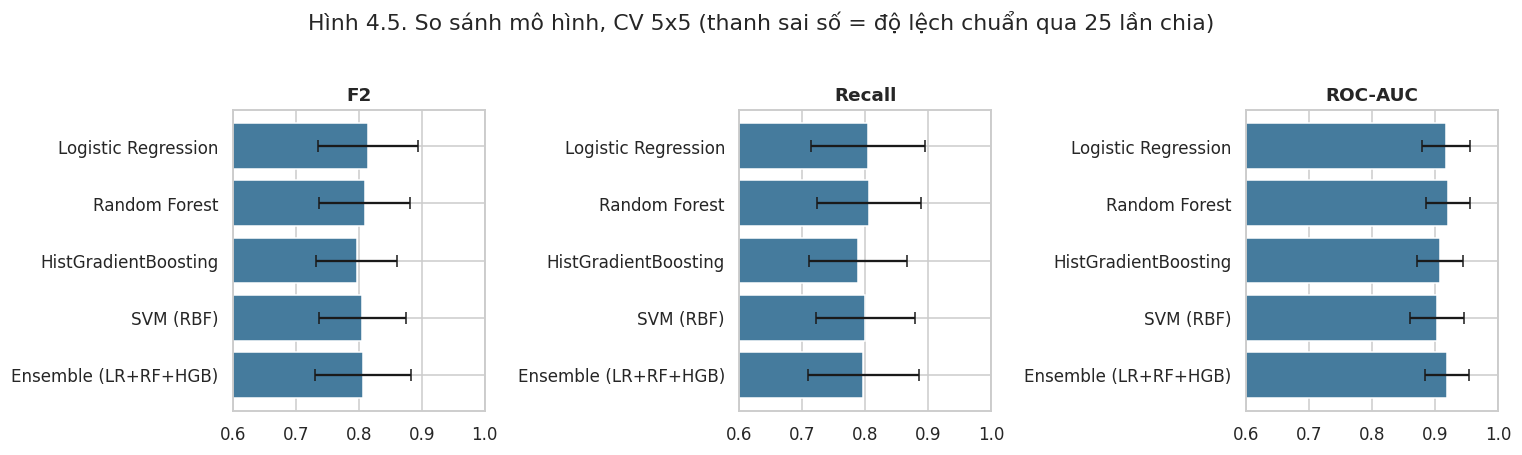

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (n, t) in zip(ax, [('f2', 'F2'), ('recall', 'Recall'), ('roc_auc', 'ROC-AUC')]):
    mu = [raw[k]['test_'+n].mean() for k in models]; sd = [raw[k]['test_'+n].std() for k in models]
    a.barh(list(models)[::-1], mu[::-1], xerr=sd[::-1], color='#457b9d', capsize=4); a.set_xlim(0.6, 1.0); a.set_title(t)
plt.suptitle('Hình 4.5. So sánh mô hình, CV 5x5 (thanh sai số = độ lệch chuẩn qua 25 lần chia)', y=1.03)
savefig('fig_4_5_so_sanh_cv_lap')

**Đọc kết quả:** độ lệch chuẩn giữa các lần chia (khoảng 0,06 đến 0,09) **lớn hơn nhiều** chênh lệch giữa các mô hình. Nghĩa là năm mô hình về cơ bản **hòa nhau**. Khi hòa, nguyên tắc tiết kiệm (Occam) và yêu cầu giải thích được trong y tế dẫn tới chọn **Logistic Regression**: đơn giản nhất, Precision và Brier tốt nhất trong nhóm, hệ số giải thích được từng ca.

## 2. Chọn ngưỡng quyết định theo mục tiêu Recall (nested CV)
Ngưỡng 0,5 mặc định không gắn với mục tiêu y tế. Ta thử ba quy tắc, chọn ngưỡng **chỉ từ dữ liệu train của từng fold** (bằng dự đoán out-of-fold bên trong), rồi áp dụng lên fold test. Nhờ vậy ước lượng không bị lạc quan do chọn ngưỡng trên chính dữ liệu đánh giá.

In [4]:
GRID = np.round(np.arange(0.15, 0.80, 0.025), 3)
def oof_proba(Xa, ya, seed=0):
    return cross_val_predict(P(LR()), Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba')[:, 1]
def thr_f2(oof, ya):
    s = np.array([fbeta_score(ya, oof >= t, beta=2) for t in GRID]); return GRID[int(np.argmax(np.convolve(s, np.ones(3)/3, mode='same')))]
def thr_recall(oof, ya, target=0.90):
    ok = [t for t in GRID if recall_score(ya, oof >= t) >= target]; return max(ok) if ok else GRID[0]
rules = {'Ngưỡng 0,5 (mặc định)': lambda o, a: 0.5, 'Tối đa hóa F2': thr_f2, 'Recall >= 0,90 (Precision cao nhất)': thr_recall}
out = {k: [] for k in rules}; chosen = {k: [] for k in rules}
for tr, te in cv.split(X, y):
    Xa, ya, Xb, yb = X.iloc[tr], y.iloc[tr], X.iloc[te], y.iloc[te]
    p = P(LR()).fit(Xa, ya).predict_proba(Xb)[:, 1]; oo = oof_proba(Xa, ya)
    for k, f in rules.items():
        t = f(oo, ya); chosen[k].append(t); pr = p >= t
        out[k].append((recall_score(yb, pr), precision_score(yb, pr), f1_score(yb, pr), fbeta_score(yb, pr, beta=2)))
thr_tab = pd.DataFrame({k: dict(zip(['Recall', 'Precision', 'F1', 'F2'], np.array(v).mean(0))) | {'Ngưỡng TB': np.mean(chosen[k]), 'Recall (độ lệch chuẩn)': np.array(v)[:, 0].std()} for k, v in out.items()}).T.round(3)
thr_tab.to_csv(ROOT / 'report' / 'bang_nested_nguong.csv'); thr_tab

,Recall,Precision,F1,F2,Ngưỡng TB,Recall (độ lệch chuẩn)
"Ngưỡng 0,5 (mặc định)",0.804,0.873,0.834,0.815,0.500,0.090
Tối đa hóa F2,0.961,0.652,0.775,0.876,0.242,0.048
"Recall >= 0,90 (Precision cao nhất)",0.897,0.727,0.801,0.855,0.342,0.077


Đây là **đánh đổi chính sách**, không phải có đáp án đúng duy nhất: hạ ngưỡng làm Recall tăng nhưng Precision giảm (nhiều người khỏe bị báo nhầm). Bài chọn quy tắc **Recall >= 0,90** làm chế độ sàng lọc vì dễ phát biểu và dễ giải thích hơn việc tối đa hóa F2.

Ngưỡng sàng lọc (Recall >= 0,90 trên dự đoán out-of-fold toàn bộ dữ liệu): 0.35


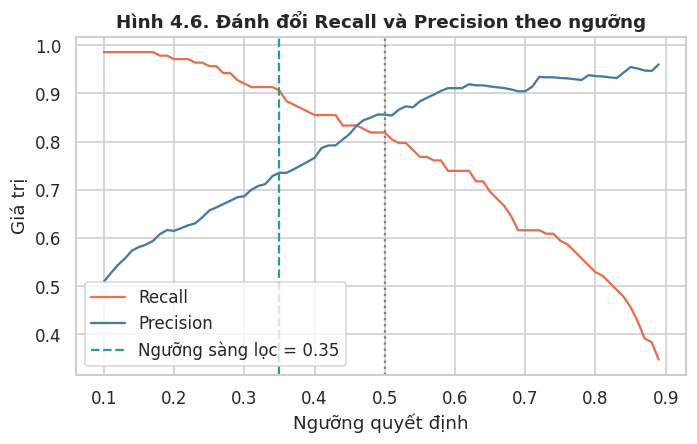

In [5]:
oof_all = np.mean([oof_proba(X, y, seed=s) for s in range(5)], axis=0)
ts = np.arange(0.1, 0.9, 0.01)
rc = [recall_score(y, oof_all >= t) for t in ts]; pc = [precision_score(y, oof_all >= t) for t in ts]
T_FINAL = float(thr_recall(oof_all, y)); print('Ngưỡng sàng lọc (Recall >= 0,90 trên dự đoán out-of-fold toàn bộ dữ liệu):', T_FINAL)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(ts, rc, label='Recall', color='#e76f51'); ax.plot(ts, pc, label='Precision', color='#457b9d')
ax.axvline(0.5, ls=':', color='gray'); ax.axvline(T_FINAL, ls='--', color='#2a9d8f', label=f'Ngưỡng sàng lọc = {T_FINAL:.2f}')
ax.set_xlabel('Ngưỡng quyết định'); ax.set_ylabel('Giá trị'); ax.set_title('Hình 4.6. Đánh đổi Recall và Precision theo ngưỡng'); ax.legend()
savefig('fig_4_6_danh_doi_nguong')

## 3. Hiệu chuẩn xác suất
Ứng dụng hiển thị xác suất (%), nên cần kiểm tra xác suất có đáng tin không: trong số người được dự đoán 30% thì có khoảng 30% thật sự mắc bệnh hay không.

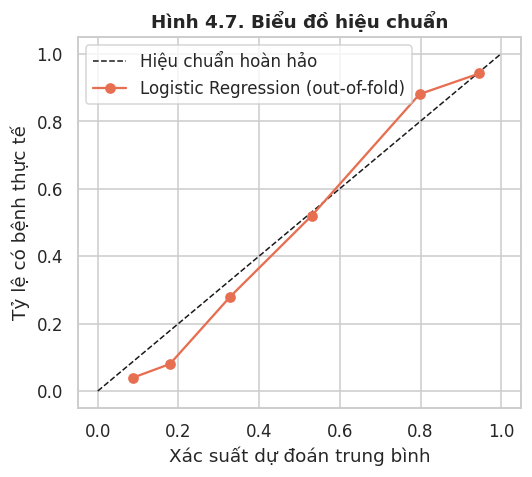

Brier = 0.117 (mô hình luôn đoán tỷ lệ nền: 0.248)
   Dự đoán TB  Thực tế
0       0.086    0.039
1       0.179    0.080
2       0.328    0.280
3       0.530    0.520
4       0.798    0.880
5       0.946    0.941


In [6]:
fp, mp = calibration_curve(y, oof_all, n_bins=6, strategy='quantile')
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Hiệu chuẩn hoàn hảo'); ax.plot(mp, fp, 'o-', color='#e76f51', label='Logistic Regression (out-of-fold)')
ax.set_xlabel('Xác suất dự đoán trung bình'); ax.set_ylabel('Tỷ lệ có bệnh thực tế'); ax.set_title('Hình 4.7. Biểu đồ hiệu chuẩn'); ax.legend()
savefig('fig_4_7_hieu_chuan')
br = brier_score_loss(y, oof_all); base = brier_score_loss(y, np.full(len(y), y.mean()))
print(f'Brier = {br:.3f} (mô hình luôn đoán tỷ lệ nền: {base:.3f})')
print(pd.DataFrame({'Dự đoán TB': mp.round(3), 'Thực tế': fp.round(3)}))

## 4. Kiểm tra trên tập test giữ riêng, khoảng tin cậy và nhóm giới tính
Chia 80/20 như notebook 03 (cùng `random_state`). Ngưỡng chọn chỉ từ train. Tập test chỉ dùng **một lần**.

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
m = P(LR()).fit(Xtr, ytr); p = m.predict_proba(Xte)[:, 1]
t_tr = float(thr_recall(oof_proba(Xtr, ytr), ytr)); print('Ngưỡng chọn chỉ từ train:', t_tr)
rng = np.random.default_rng(RANDOM_STATE); yt = yte.values
def boot(f, n=2000):
    v = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if len(set(yt[i])) < 2: continue
        v.append(f(yt[i], p[i]))
    return np.percentile(v, [2.5, 97.5])
rows = []
for name, t in [('Ngưỡng 0,5', 0.5), (f'Ngưỡng sàng lọc {t_tr:.2f}', t_tr)]:
    pr = p >= t; ci = boot(lambda a, b: recall_score(a, b >= t))
    rows.append({'Chế độ': name, 'Recall': recall_score(yt, pr), 'KTC 95% Recall': f'{ci[0]:.2f} đến {ci[1]:.2f}', 'Precision': precision_score(yt, pr), 'Bỏ sót (FN)': int(((~pr) & (yt == 1)).sum()), 'Báo nhầm (FP)': int((pr & (yt == 0)).sum())})
auc_ci = boot(lambda a, b: roc_auc_score(a, b))
res_tab = pd.DataFrame(rows).round(3); res_tab.to_csv(ROOT / 'report' / 'bang_test_v2.csv', index=False); display(res_tab)
print(f'ROC-AUC test = {roc_auc_score(yt, p):.3f}, KTC 95% bootstrap = {auc_ci[0]:.2f} đến {auc_ci[1]:.2f}')

Ngưỡng chọn chỉ từ train: 0.35


,Chế độ,Recall,KTC 95% Recall,Precision,Bỏ sót (FN),Báo nhầm (FP)
0,"Ngưỡng 0,5",0.786,0.62 đến 0.92,0.846,6,4
1,Ngưỡng sàng lọc 0.35,0.929,0.83 đến 1.00,0.722,2,10


ROC-AUC test = 0.924, KTC 95% bootstrap = 0.85 đến 0.98


In [8]:
sx = []
for s_, nm in [(0, 'Nữ'), (1, 'Nam')]:
    k = Xte['sex'].values == s_; pr = p[k] >= t_tr
    sx.append({'Nhóm': nm, 'n test': int(k.sum()), 'Số ca bệnh': int(yt[k].sum()), 'Recall': recall_score(yt[k], pr), 'ROC-AUC': roc_auc_score(yt[k], p[k])})
pd.DataFrame(sx).round(3)

,Nhóm,n test,Số ca bệnh,Recall,ROC-AUC
0,Nữ,17,4,1.000,1.000
1,Nam,44,24,0.917,0.888


Số ca bệnh ở nhóm nữ trong tập test rất ít (vài ca), nên kết quả theo giới **chỉ mang tính tham khảo** và không đủ để kết luận mô hình công bằng hay thiên lệch giữa hai giới. Cần dữ liệu lớn hơn để kiểm tra nghiêm túc.

## 5. Giải thích mô hình
Logistic Regression cho phép tách đóng góp của từng đặc trưng vào log-odds: `hệ số x (giá trị - giá trị trung bình)`. Với mô hình tuyến tính, đây chính là giá trị SHAP (giả định các đặc trưng độc lập). Biến One-Hot của cùng một đặc trưng gốc được cộng lại.

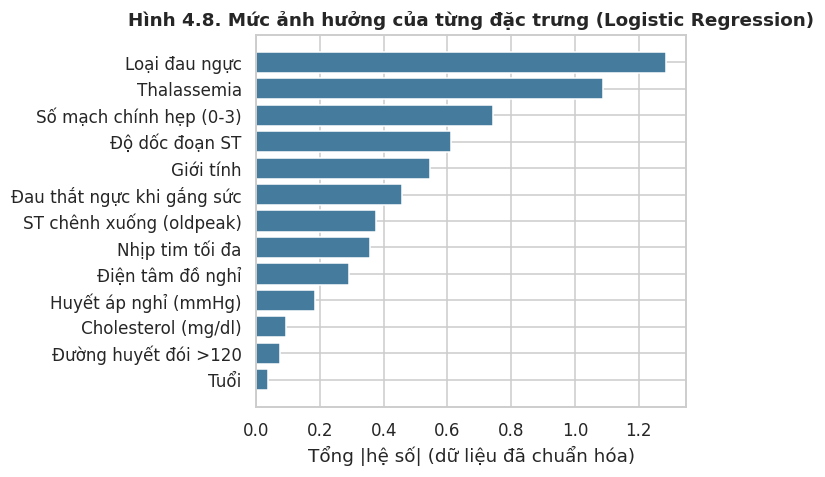

feat
cp          1.29
thal        1.09
ca          0.74
slope       0.61
sex         0.55
exang       0.46
oldpeak     0.38
thalach     0.36
restecg     0.29
trestbps    0.19
chol        0.09
fbs         0.08
age         0.04
Name: a, dtype: float64

In [9]:
final = P(LR()).fit(X, y)   # huấn luyện lại trên toàn bộ 302 mẫu cho bản triển khai
names = list(final.named_steps['prep'].get_feature_names_out()); coef = final.named_steps['clf'].coef_[0]
ref = final.named_steps['prep'].transform(X).mean(axis=0)
def orig(n):
    kind, rest = n.split('__', 1); return rest.rsplit('_', 1)[0] if kind == 'cat' else rest
g = pd.DataFrame({'feat': [orig(n) for n in names], 'coef': coef}); gi = g.assign(a=g.coef.abs()).groupby('feat').a.sum().sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4.5)); ax.barh([VN[f] for f in gi.index], gi.values, color='#457b9d')
ax.set_xlabel('Tổng |hệ số| (dữ liệu đã chuẩn hóa)'); ax.set_title('Hình 4.8. Mức ảnh hưởng của từng đặc trưng (Logistic Regression)')
savefig('fig_4_8_he_so_logistic'); gi.sort_values(ascending=False).round(2)

## 6. Lưu mô hình cuối (huấn luyện trên toàn bộ dữ liệu) và siêu dữ liệu

In [10]:
meta = {'model': 'Logistic Regression (C=0.1, class_weight=balanced)', 'features': FEATURES, 'trained_on': int(len(X)),
        'threshold_screening': T_FINAL, 'threshold_high': 0.60, 'threshold_default': 0.5,
        'transformed_names': names, 'ref_means': [float(v) for v in ref],
        'cv5x5_metrics': {k: round(float(raw['Logistic Regression']['test_'+k].mean()) * (-1 if k == 'brier' else 1), 4) for k in sc},
        'nested_threshold_metrics': thr_tab.loc['Recall >= 0,90 (Precision cao nhất)'].to_dict(),
        'note': 'Số liệu đánh giá lấy từ nested CV/test giữ riêng; mô hình lưu là bản huấn luyện lại trên toàn bộ dữ liệu.'}
joblib.dump(final, MODELS / 'model_final.joblib'); json.dump(meta, open(MODELS / 'model_final_meta.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
assert np.allclose(joblib.load(MODELS / 'model_final.joblib').predict_proba(X), final.predict_proba(X))
print('Đã lưu models/model_final.joblib | ngưỡng sàng lọc =', T_FINAL)

Đã lưu models/model_final.joblib | ngưỡng sàng lọc = 0.35
